In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Arc, Circle, Rectangle

In [8]:
def draw_court(ax=None, color='black', lw=2, outer_lines=False):
    if ax is None:
        ax = plt.gca()

    # Create the various elements of an NBA basketball court
    # Dimensions are in feet, but the drawing is scaled to fit nicely on a standard plot
    # Scaled by a factor of 10 for better visibility (1 foot = 10 units)

    floor = Rectangle((-250, -40), 500, 470, linewidth=lw, color=color, fill=False)
    # 3 feet from to the left from the hoop (-30) then stretches 6 feet to the right (30) and is 1 foot thick (-1) for visual purposes
    backboard = Rectangle((-30, -7.5), 60, -1, linewidth=lw, color=color)
    hoop = Circle((0, 0), radius=7.5, linewidth=lw, color=color, fill=False)

    # -40 is the bottom of the court
    outer_box = Rectangle((-80, -40), 160, 190, linewidth=lw, color=color, fill=False)
    inner_box = Rectangle((-60, -40), 120, 190, linewidth=lw, color=color, fill=False)

    # Free throw top arc
    # 15 feet from the center of the hoop
    top_free_throw = Arc((0, 150), 120, 120, theta1=0, theta2=180, linewidth=lw, color=color, fill=False)
    # Free throw bottom dashed arc
    bottom_free_throw = Arc((0, 150), 120, 120, theta1=180, theta2=0, linewidth=lw, color=color, linestyle='dashed')

    # Restricted Zone in front of the hoop
    restricted = Arc((0, 0), 80, 80, theta1=0, theta2=180, linewidth=lw, color=color)

    # Three point line
    corner_three_a = Rectangle((-220, -40), 0, 100, linewidth=lw, color=color)
    corner_three_b = Rectangle((220, -40), 0, 100, linewidth=lw, color=color)
    three_arc = Arc((0, 0), 456, 456,theta1=15, theta2=165,linewidth=lw, color=color)

    # Center court arcs
    center_outer_arc = Arc((0, 430), 120, 120, theta1=180, theta2=0, linewidth=lw, color=color)
    center_inner_arc = Arc((0, 430), 40, 40, theta1=180, theta2=0, linewidth=lw, color=color)

    ax.set_aspect('equal')

    # List of the court elements to be plotted onto the axes
    court_elements = [floor,hoop, backboard, outer_box, inner_box, top_free_throw,
                      bottom_free_throw, restricted, corner_three_a,
                      corner_three_b, three_arc, center_outer_arc,
                      center_inner_arc]


    # Add the court elements onto the axes
    for element in court_elements:
        ax.add_patch(element)

    return ax

In [10]:
import pandas as pd
import numpy as np

player = "Dyson Daniels"

conn = get_connection()

query = """
SELECT EVENT_TYPE, LOC_X, LOC_Y
FROM dbo.shotchartdetail
WHERE PLAYER_NAME = ?
"""

df = pd.read_sql_query(query, conn, params=[player])
conn.close()

df["LOC_X"] = pd.to_numeric(df["LOC_X"], errors="coerce")
df["LOC_Y"] = pd.to_numeric(df["LOC_Y"], errors="coerce")
df = df.dropna(subset=["LOC_X", "LOC_Y"])

made = df[df["EVENT_TYPE"] == "Made Shot"]
missed = df[df["EVENT_TYPE"] == "Missed Shot"]

print("Total shots:", len(df))
print("Made shots:", len(made))
print("Missed shots:", len(missed))
print("FG%:", round(np.mean(df["EVENT_TYPE"] == "Made Shot") * 100, 1))

Total shots: 777
Made shots: 402
Missed shots: 375
FG%: 51.7


/var/folders/fc/bnpj_mv12fl5xq1jsfqrlz6h0000gn/T/ipykernel_3820/1470227100.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql_query(query, conn, params=[player])


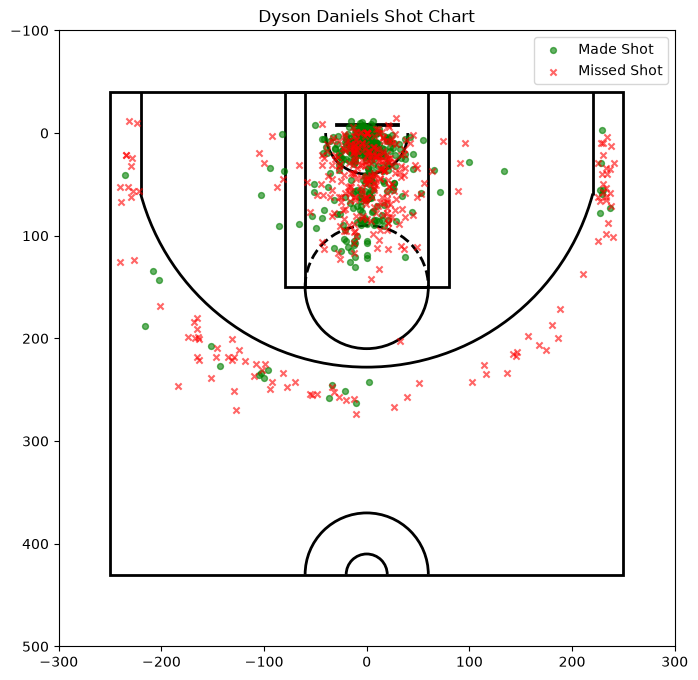

In [11]:
# Plot the court
plt.figure(figsize=(8, 8))
draw_court()

plt.xlim(-300, 300)
plt.ylim(500, -100)

# Made shots
plt.scatter(
    made["LOC_X"],
    made["LOC_Y"],
    color="green",
    s=18,
    alpha=0.6,
    label="Made Shot"
)

# Missed shots
plt.scatter(
    missed["LOC_X"],
    missed["LOC_Y"],
    color="red",
    marker="x",
    s=20,
    alpha=0.6,
    label="Missed Shot"
)

plt.title(f"{player} Shot Chart")
plt.legend()
plt.show()

In [1]:
import os
import pyodbc

print("OpenSSL:", os.getenv("DYLD_LIBRARY_PATH"))
print("Drivers:", pyodbc.drivers())

OpenSSL: /opt/homebrew/opt/openssl@3/lib
Drivers: ['ODBC Driver 18 for SQL Server']


In [2]:
from sql_client_mac import get_connection

conn = get_connection()
print("SQL Server connected successfully!")
conn.close()

SQL Server connected successfully!


ALL WORKING CODE IS ABOVE
Code below is used just for testing *YOU CAN IGNORE IT*

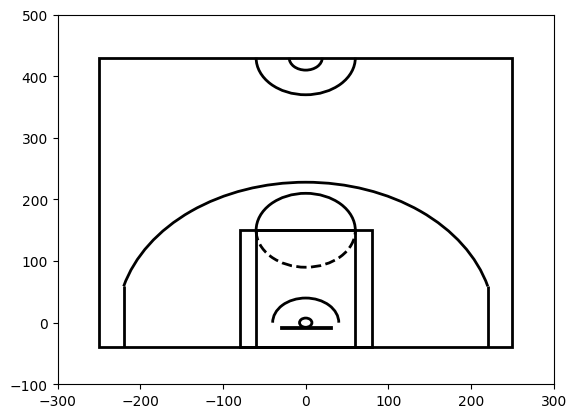

In [76]:
# Testing
lw = 2
color = 'black'

floor = Rectangle((-250, -40), 500, 470, linewidth=lw, color=color, fill=False)
# 3 feet from to the left from the hoop (-30) then stretches 6 feet to the right (30) and is 1 foot thick (-1) for visual purposes
backboard = Rectangle((-30, -7.5), 60, -1, linewidth=lw, color=color)
hoop = Circle((0, 0), radius=7.5, linewidth=lw, color=color, fill=False)

# -40 is the bottom of the court
outer_box = Rectangle((-80, -40), 160, 190, linewidth=lw, color=color, fill=False)
inner_box = Rectangle((-60, -40), 120, 190, linewidth=lw, color=color, fill=False)

# Free throw top arc
# 15 feet from the center of the hoop
top_free_throw = Arc((0, 150), 120, 120, theta1=0, theta2=180, linewidth=lw, color=color, fill=False)
# Free throw bottom dashed arc
bottom_free_throw = Arc((0, 150), 120, 120, theta1=180, theta2=0, linewidth=lw, color=color, linestyle='dashed')

# Restricted Zone in front of the hoop
restricted = Arc((0, 0), 80, 80, theta1=0, theta2=180, linewidth=lw, color=color)

corner_three_a = Rectangle((-220, -40), 0, 100, linewidth=lw, color=color)
corner_three_b = Rectangle((220, -40), 0, 100, linewidth=lw, color=color)
three_arc = Arc((0, 0), 456, 456,theta1=15, theta2=165,linewidth=lw, color=color)

center_outer_arc = Arc((0, 430), 120, 120, theta1=180, theta2=0, linewidth=lw, color=color)
center_inner_arc = Arc((0, 430), 40, 40, theta1=180, theta2=0, linewidth=lw, color=color)

plt.gca().add_patch(floor)
plt.gca().add_patch(backboard)
plt.gca().add_patch(hoop)
plt.gca().add_patch(outer_box)
plt.gca().add_patch(inner_box)
plt.gca().add_patch(top_free_throw)
plt.gca().add_patch(bottom_free_throw)
plt.gca().add_patch(restricted)
plt.gca().add_patch(corner_three_a)
plt.gca().add_patch(corner_three_b)
plt.gca().add_patch(three_arc)
plt.gca().add_patch(center_outer_arc)
plt.gca().add_patch(center_inner_arc)
plt.xlim(-300,300)
plt.ylim(-100,500)
plt.show()